In [20]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from pathlib import Path
import random
import shutil
import time


In [21]:
# settings
seed=42
batch_size =64
epochs= 10
lr = 0.001
weight_decay=0.0001
DATA_DIR = Path('../data')

Path('figures').mkdir(exist_ok=True)
Path('results').mkdir(exist_ok=True)

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark=False

device= torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
if device.type == 'cuda':
    torch.cuda.manual_seed_all(seed)
    print(torch.cuda.get_device_name(0))
else:
    raise RuntimeError('GPU required for this lab. Check CUDA before continuing.')


cuda
NVIDIA GeForce RTX 3060 Laptop GPU


In [22]:
# local IDX files
raw_dir = DATA_DIR / 'MNIST' / 'raw'
supplied_dir = Path('../data/MINST')
idx_names = {
    'train-images-idx3-ubyte': 'train-images.idx3-ubyte',
    'train-labels-idx1-ubyte': 'train-labels.idx1-ubyte',
    't10k-images-idx3-ubyte': 't10k-images.idx3-ubyte',
    't10k-labels-idx1-ubyte': 't10k-labels.idx1-ubyte',
}
for expected, supplied in idx_names.items():
    destination = raw_dir / expected
    if not destination.exists():
        candidates = [supplied_dir / supplied, supplied_dir / expected, supplied_dir / expected / expected]
        source = next((candidate for candidate in candidates if candidate.is_file()), None)
        if source is not None:
            raw_dir.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(source, destination)


In [23]:
# MNIST
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])
mnist_train = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
test_data = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)
train_data, val_data = random_split(
    mnist_train, [55000, 5000], generator=torch.Generator().manual_seed(seed)
)


In [24]:
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                          generator=torch.Generator().manual_seed(seed))
val_loader= DataLoader(val_data,batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_data, batch_size=batch_size,shuffle=False)

print(len(train_data), len(val_data), len(test_data))


55000 5000 10000


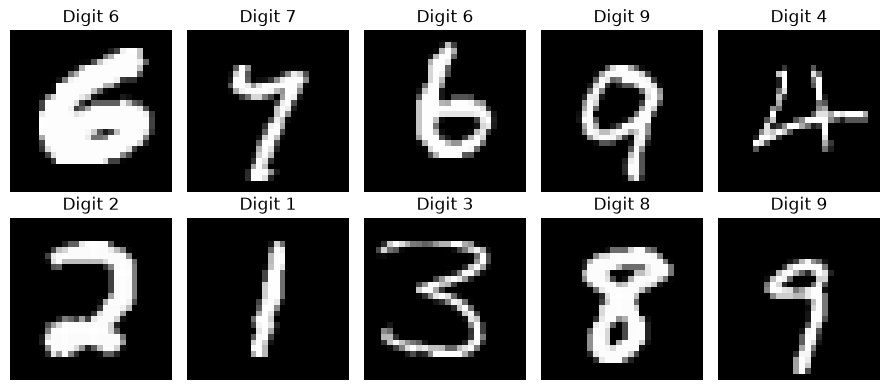

In [25]:
# sample images
images, labels = next(iter(DataLoader(train_data, batch_size=10, shuffle=False)))
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for index, ax in enumerate(axes.flat):
    ax.imshow(images[index, 0] * 0.3081 + 0.1307, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'Digit {labels[index].item()}')
    ax.axis('off')
plt.tight_layout()
fig.savefig('figures/cnn_samples.png', dpi=300, bbox_inches='tight')
plt.show()


In [26]:
# CNN
class MNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1= nn.Conv2d(1,32, kernel_size=3, stride=1,padding=1)
        self.conv2 = nn.Conv2d(32,64,kernel_size=3, stride=1, padding=1)
        self.pool=nn.MaxPool2d(2,2)
        self.relu = nn.ReLU()
        self.dropout2d = nn.Dropout2d(0.25)
        self.fc1 = nn.Linear(64*7*7,128)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.dropout2d(x)
        x = torch.flatten(x, 1)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)


In [27]:
# training
def train_model(train_dl, model, criterion, optimizer):
    model.train()
    total_loss, correct,total= 0.0,0,0

    for inputs, targets in train_dl:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        yhat= model(inputs)
        loss = criterion(yhat, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * targets.size(0)
        correct += (yhat.argmax(dim=1) == targets).sum().item()
        total += targets.size(0)

    return {'loss': total_loss / total, 'accuracy': correct / total}


In [28]:
# evaluation
def evaluate_model(test_dl, model, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    actuals, predictions = [], []

    with torch.no_grad():
        for inputs, targets in test_dl:
            inputs = inputs.to(device)
            targets = targets.to(device)
            yhat = model(inputs)
            loss = criterion(yhat, targets)
            predicted = yhat.argmax(dim=1)

            total_loss += loss.item() * targets.size(0)
            correct += (predicted == targets).sum().item()
            total += targets.size(0)

            actuals.extend(targets.cpu().tolist())
            predictions.extend(predicted.cpu().tolist())

    return {'loss': total_loss/total, 'accuracy': correct/total,
            'targets': actuals, 'predictions': predictions}


In [29]:
torch.manual_seed(seed)
train_loader.generator.manual_seed(seed)
model= MNISTCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer= torch.optim.Adam(model.parameters(),lr=lr, weight_decay=weight_decay)
print(model)


MNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (dropout2d): Dropout2d(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [30]:
# training time excludes validation
history=[]
best_loss = float('inf')
best_epoch=0
training_time = 0

for epoch in range(epochs):
    torch.cuda.synchronize()
    start= time.perf_counter()
    train_stats = train_model(train_loader, model, criterion,optimizer)
    torch.cuda.synchronize()
    training_time += time.perf_counter()-start

    val_stats= evaluate_model(val_loader,model,criterion)
    history.append([epoch+1, train_stats['loss'], val_stats['loss'],
                    train_stats['accuracy'], val_stats['accuracy']])

    if val_stats['loss'] < best_loss:
        best_loss=val_stats['loss']
        best_epoch = epoch+1
        torch.save(model.state_dict(), 'results/cnn_best.pt')

    print(f"Epoch {epoch+1}/{epochs} - loss: {train_stats['loss']:.4f}, "
          f"val loss: {val_stats['loss']:.4f}, "
          f"accuracy: {train_stats['accuracy']:.4f}, val accuracy: {val_stats['accuracy']:.4f}")

history_df= pd.DataFrame(history,columns=['epoch','train_loss','val_loss',
                                         'train_accuracy','val_accuracy'])
history_df.to_csv('results/cnn_history.csv', index=False)
print('Best epoch:',best_epoch)
print('Training time:', round(training_time,2), 's')


Epoch 1/10 - loss: 0.2571, val loss: 0.0702, accuracy: 0.9201, val accuracy: 0.9806
Epoch 2/10 - loss: 0.1015, val loss: 0.0506, accuracy: 0.9706, val accuracy: 0.9866
Epoch 3/10 - loss: 0.0767, val loss: 0.0505, accuracy: 0.9778, val accuracy: 0.9856
Epoch 4/10 - loss: 0.0638, val loss: 0.0485, accuracy: 0.9808, val accuracy: 0.9872
Epoch 5/10 - loss: 0.0582, val loss: 0.0373, accuracy: 0.9821, val accuracy: 0.9902
Epoch 6/10 - loss: 0.0513, val loss: 0.0405, accuracy: 0.9844, val accuracy: 0.9884
Epoch 7/10 - loss: 0.0489, val loss: 0.0393, accuracy: 0.9851, val accuracy: 0.9876
Epoch 8/10 - loss: 0.0441, val loss: 0.0395, accuracy: 0.9865, val accuracy: 0.9894
Epoch 9/10 - loss: 0.0421, val loss: 0.0359, accuracy: 0.9860, val accuracy: 0.9904
Epoch 10/10 - loss: 0.0386, val loss: 0.0368, accuracy: 0.9880, val accuracy: 0.9892
Best epoch: 9
Training time: 41.54 s


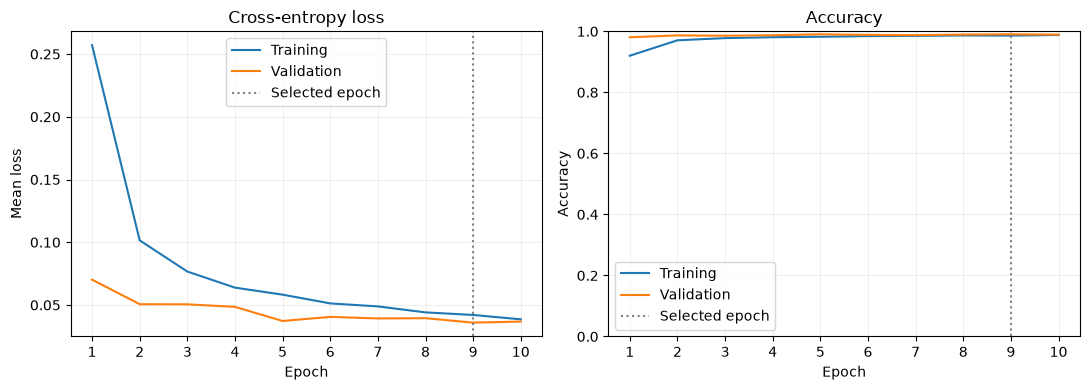

In [31]:
# loss and accuracy
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Training')
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='Validation')
axes[0].set(title='Cross-entropy loss', xlabel='Epoch', ylabel='Mean loss')
axes[1].plot(history_df['epoch'], history_df['train_accuracy'], label='Training')
axes[1].plot(history_df['epoch'], history_df['val_accuracy'], label='Validation')
axes[1].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1))
for ax in axes:
    ax.axvline(best_epoch, color='gray', linestyle=':', label='Selected epoch')
    ax.set_xticks(history_df['epoch'])
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
fig.savefig('figures/cnn_learning_curves.png', dpi=300, bbox_inches='tight')
plt.show()


In [32]:
# test the saved model
model.load_state_dict(torch.load('results/cnn_best.pt', map_location=device,weights_only=True))
test_stats= evaluate_model(test_loader, model,criterion)
y_true = test_stats['targets']
y_pred= test_stats['predictions']

metrics= pd.DataFrame([{
    'model': 'CNN',
    'accuracy': accuracy_score(y_true,y_pred),
    'f1_macro': f1_score(y_true, y_pred,average='macro',zero_division=0),
    'f1_weighted': f1_score(y_true,y_pred, average='weighted', zero_division=0),
    'loss': test_stats['loss'],
    'training_time_seconds': training_time
}])
metrics.to_csv('results/cnn_metrics.csv',index=False)
print(metrics.to_string(index=False))


model  accuracy  f1_macro  f1_weighted     loss  training_time_seconds
  CNN    0.9929  0.992847     0.992896 0.021814               41.54419


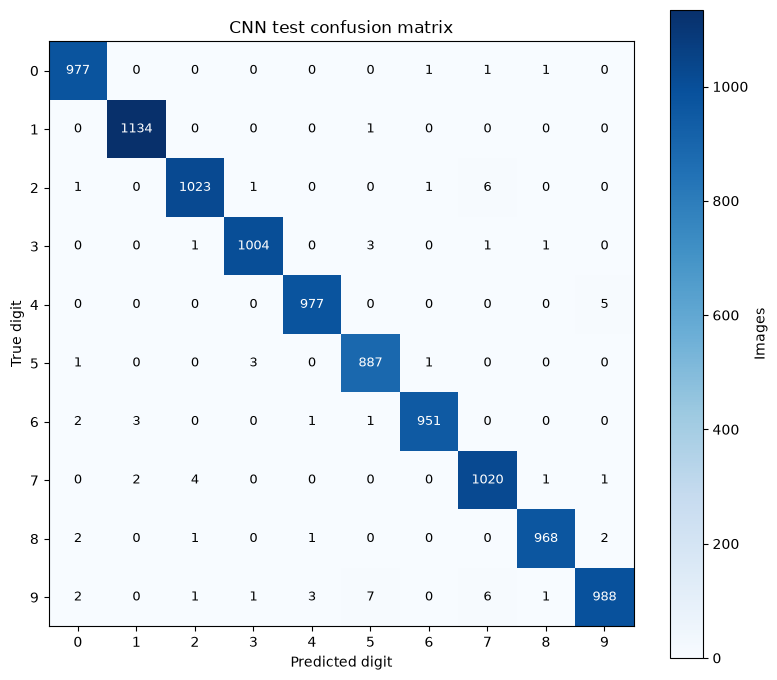

In [33]:
# confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
pd.DataFrame(cm, index=range(10), columns=range(10)).to_csv('results/cnn_confusion_matrix.csv', index_label='true_digit')
fig, ax = plt.subplots(figsize=(8, 7))
heatmap = ax.imshow(cm, cmap='Blues')
fig.colorbar(heatmap, ax=ax, label='Images')
ax.set(xticks=range(10), yticks=range(10), xlabel='Predicted digit', ylabel='True digit', title='CNN test confusion matrix')
for row in range(10):
    for column in range(10):
        ax.text(column, row, str(cm[row, column]), ha='center', va='center',
                color='white' if cm[row, column] > cm.max() / 2 else 'black', fontsize=9)
plt.tight_layout()
fig.savefig('figures/cnn_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()


In [34]:
# MNIST for Faster R-CNN
from torch.utils.data import Dataset

class MNISTDetection(Dataset):
    def __init__(self,data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self,idx):
        image,label = self.data[idx]

        # undo CNN normalization
        image= (image*0.3081 + 0.1307).clamp(0,1)
        y,x = torch.where(image[0] > 0.1)

        box = [x.min().item(), y.min().item(),
               x.max().item()+1, y.max().item()+1]

        target= {
            'boxes': torch.tensor([box],dtype=torch.float32),
            'labels': torch.tensor([int(label)+1], dtype=torch.int64)
        }

        # 3 channels; label 0 is reserved for background
        image = image.repeat(3,1,1)
        return image,target

train_detection= MNISTDetection(train_data)
val_detection = MNISTDetection(val_data)
test_detection= MNISTDetection(test_data)


In [35]:
# detection loaders
def collate_fn(batch):
    return tuple(zip(*batch))

train_det_loader= DataLoader(train_detection,batch_size=4,
                            shuffle=True, collate_fn=collate_fn)

val_det_loader = DataLoader(val_detection, batch_size=4,
                           shuffle=False,collate_fn=collate_fn)

test_det_loader= DataLoader(test_detection,batch_size=4,
                           shuffle=False, collate_fn=collate_fn)


In [36]:
# Faster R-CNN
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

backbone= nn.Sequential(
    nn.Conv2d(3,32, kernel_size=3,padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32,64,kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2)
)
backbone.out_channels =64

anchors= AnchorGenerator(
    sizes=((8,16,24),),
    aspect_ratios=((0.5,1.0,2.0),)
)

roi_pool = MultiScaleRoIAlign(
    featmap_names=['0'],output_size=7, sampling_ratio=2
)

rcnn= FasterRCNN(
    backbone, num_classes=11,
    rpn_anchor_generator=anchors,
    box_roi_pool=roi_pool,
    min_size=28,max_size=28,
    image_mean=[0.1307]*3,
    image_std=[0.3081]*3
).to(device)

optimizer_rcnn = torch.optim.Adam(rcnn.parameters(),lr=0.001)


In [37]:
# train one epoch
def train_rcnn(loader,model,optimizer):
    model.train()
    total_loss=0
    total = 0

    for images,targets in loader:
        images= [img.to(device) for img in images]
        targets = [{k:v.to(device) for k,v in t.items()}
                   for t in targets]

        optimizer.zero_grad()
        losses= model(images,targets)
        loss = sum(losses.values())
        loss.backward()
        optimizer.step()

        total_loss += loss.item()*len(images)
        total += len(images)

    return total_loss/total


In [39]:
# validation and test
def evaluate_rcnn(loader,model):
    model.eval()
    y_true,y_pred = [],[]

    with torch.no_grad():
        for images,targets in loader:
            images= [img.to(device) for img in images]
            outputs = model(images)

            for output,target in zip(outputs,targets):
                label= target['labels'][0].item()-1
                y_true.append(label)

                if len(output['scores']) > 0:
                    i = output['scores'].argmax().item()
                    pred= output['labels'][i].item()-1
                else:
                    pred = -1  # no detection counts as an error

                y_pred.append(pred)

    return accuracy_score(y_true,y_pred), y_true,y_pred


In [40]:
from tqdm.auto import tqdm

rcnn_history=[]
best_acc = -1
rcnn_training_time=0

for epoch in range(10):
    torch.cuda.synchronize()
    start= time.perf_counter()

    loss = train_rcnn(tqdm(train_det_loader,desc=f'Epoch {epoch+1}'),
                      rcnn,optimizer_rcnn)

    torch.cuda.synchronize()
    rcnn_training_time += time.perf_counter()-start

    val_acc,_,_ = evaluate_rcnn(val_det_loader,rcnn)
    rcnn_history.append([epoch+1,loss,val_acc])

    if val_acc > best_acc:
        best_acc=val_acc
        torch.save(rcnn.state_dict(),'results/rcnn_best.pt')

    print(f'Loss: {loss:.4f}, val accuracy: {val_acc:.4f}')

rcnn_history = pd.DataFrame(rcnn_history,
                           columns=['epoch','train_loss','val_accuracy'])
rcnn_history.to_csv('results/rcnn_history.csv',index=False)

print('Training time:',round(rcnn_training_time,2),'s')


Epoch 1:   0%|          | 0/13750 [00:00<?, ?it/s]

Loss: 0.0753, val accuracy: 0.9820


Epoch 2:   0%|          | 0/13750 [00:00<?, ?it/s]

Loss: 0.0446, val accuracy: 0.9786


Epoch 3:   0%|          | 0/13750 [00:00<?, ?it/s]

Loss: 0.0357, val accuracy: 0.9848


... (10 outputs left out)

Epoch 9:   0%|          | 0/13750 [00:00<?, ?it/s]

Loss: 0.0287, val accuracy: 0.9892


Epoch 10:   0%|          | 0/13750 [00:00<?, ?it/s]

Loss: 0.0287, val accuracy: 0.9890
Training time: 2644.91 s


In [41]:
# test Faster R-CNN
rcnn.load_state_dict(torch.load('results/rcnn_best.pt',
                               map_location=device,weights_only=True))

test_acc,y_true_rcnn,y_pred_rcnn = evaluate_rcnn(test_det_loader,rcnn)

rcnn_metrics= pd.DataFrame([{
    'model': 'Faster R-CNN',
    'accuracy': test_acc,
    'f1_macro': f1_score(y_true_rcnn,y_pred_rcnn, labels=list(range(10)),
                         average='macro',zero_division=0),
    'f1_weighted': f1_score(y_true_rcnn,y_pred_rcnn,labels=list(range(10)),
                            average='weighted',zero_division=0),
    'training_time_seconds': rcnn_training_time
}])

rcnn_metrics.to_csv('results/rcnn_metrics.csv',index=False)
print(rcnn_metrics.to_string(index=False))


       model  accuracy  f1_macro  f1_weighted  training_time_seconds
Faster R-CNN     0.989  0.988977     0.988982            2644.909476


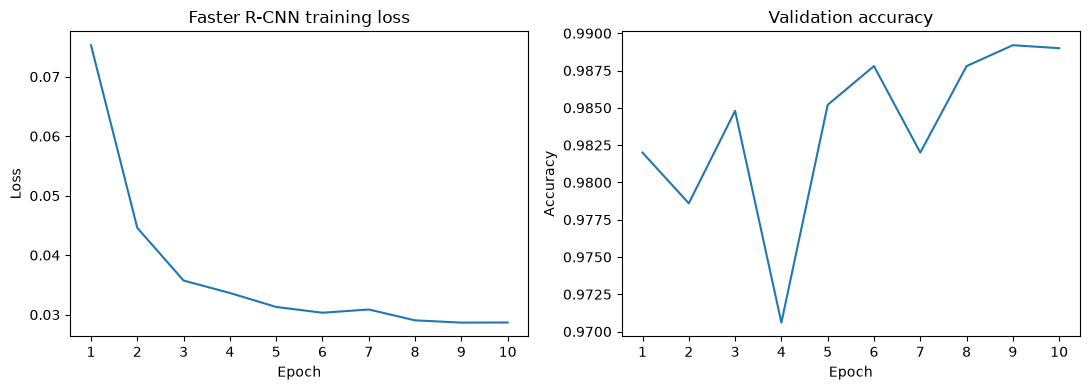

In [42]:
# learning curves
fig,ax = plt.subplots(1,2,figsize=(11,4))

ax[0].plot(rcnn_history['epoch'],rcnn_history['train_loss'])
ax[0].set_title('Faster R-CNN training loss')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Loss')

ax[1].plot(rcnn_history['epoch'], rcnn_history['val_accuracy'])
ax[1].set_title('Validation accuracy')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')

for a in ax:
    a.set_xticks(rcnn_history['epoch'])

plt.tight_layout()
plt.savefig('figures/rcnn_learning_curves.png',dpi=300,bbox_inches='tight')
plt.show()


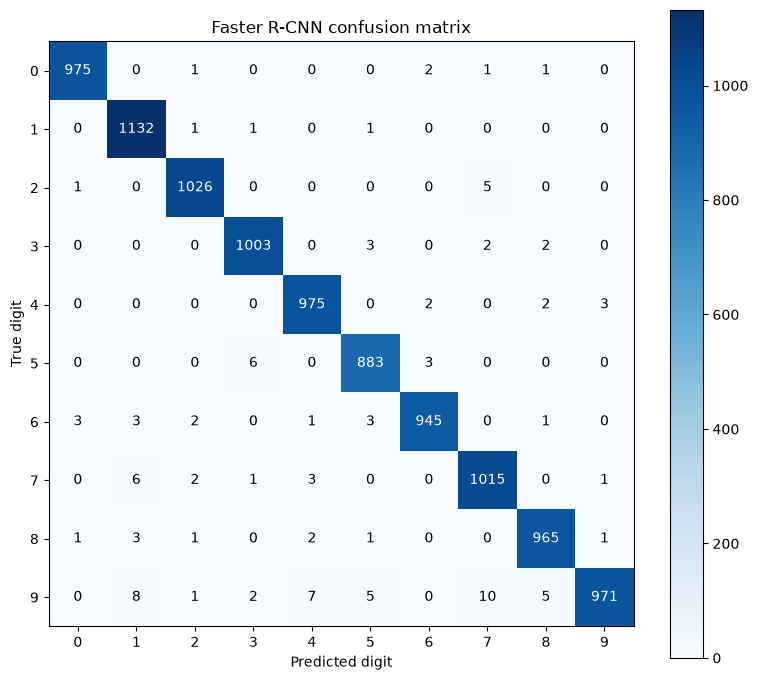

In [43]:
# confusion matrix (-1 means no detection)
labels= list(range(10))
if -1 in y_pred_rcnn:
    labels = [-1]+labels

cm= confusion_matrix(y_true_rcnn,y_pred_rcnn,labels=labels)
pd.DataFrame(cm,index=labels,columns=labels).to_csv(
    'results/rcnn_confusion_matrix.csv',index_label='True digit'
)

fig,ax = plt.subplots(figsize=(8,7))
im= ax.imshow(cm,cmap='Blues')
fig.colorbar(im,ax=ax)

ax.set_xticks(range(len(labels)),labels=labels)
ax.set_yticks(range(len(labels)),labels=labels)
ax.set_xlabel('Predicted digit')
ax.set_ylabel('True digit')
ax.set_title('Faster R-CNN confusion matrix')

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',
                color='white' if cm[i,j]>cm.max()/2 else 'black')

plt.tight_layout()
plt.savefig('figures/rcnn_confusion_matrix.png',dpi=300,bbox_inches='tight')
plt.show()
